# Optional Lab: Gradient Descent for Linear Regression

<figure>
    <center> <img src="./images/C1_W1_L4_S1_Lecture_GD.png"  style="width:800px;height:200px;" ></center>
</figure>

## Goals
In this lab, you will:
- automate the process of optimizing $w$ and $b$ using gradient descent.

## Tools
In this lab, we will make use of: 
- NumPy, a popular library for scientific computing
- Matplotlib, a popular library for plotting data
- plotting routines in the lab_utils.py file in the local directory

In [2]:
import math, copy
import numpy as np
import matplotlib.pyplot as plt

<a name="toc_40291_2"></a>
# Problem Statement

Let's use the same two data points as before - a house with 1000 square feet sold for \\$300,000 and a house with 2000 square feet sold for \\$500,000.

| Size (1000 sqft)     | Price (1000s of dollars) |
| ----------------| ------------------------ |
| 1               | 300                      |
| 2               | 500                      |


In [3]:
# Load our data set
x_train = np.array([0,1,2,3])   #features
y_train = np.array([1,3,5,7])   #target value

<a name="toc_40291_2.0.1"></a>
### Compute_Cost
This was developed in the last lab. We'll need it again here.

In [16]:
#Function to calculate the cost
def compute_cost(x, y, w, b):
   
    m = x.shape[0] 
    cost = 0
    
    for i in range(m):
        f_wb = w * x[i] + b
        cost = cost + (f_wb - y[i])**2
    total_cost = 1 / (2 * m) * cost

    return total_cost

<a name="toc_40291_2.1"></a>
## Gradient descent summary
So far in this course, you have developed a linear model that predicts $f_{w,b}(x^{(i)})$:
$$f_{w,b}(x^{(i)}) = wx^{(i)} + b \tag{1}$$
In linear regression, you utilize input training data to fit the parameters $w$,$b$ by minimizing a measure of the error between our predictions $f_{w,b}(x^{(i)})$ and the actual data $y^{(i)}$. The measure is called the $cost$, $J(w,b)$. In training you measure the cost over all of our training samples $x^{(i)},y^{(i)}$
$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2\tag{2}$$ 


In lecture, *gradient descent* was described as:

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline
\;  w &= w -  \alpha \frac{\partial J(w,b)}{\partial w} \tag{3}  \; \newline 
 b &= b -  \alpha \frac{\partial J(w,b)}{\partial b}  \newline \rbrace
\end{align*}$$
where, parameters $w$, $b$ are updated simultaneously.  
The gradient is defined as:
$$
\begin{align}
\frac{\partial J(w,b)}{\partial w}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)} \tag{4}\\
  \frac{\partial J(w,b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \tag{5}\\
\end{align}
$$

Here *simultaniously* means that you calculate the partial derivatives for all the parameters before updating any of the parameters.

<a name="toc_40291_2.2"></a>
## Implement Gradient Descent
You will implement gradient descent algorithm for one feature. You will need three functions. 
- `compute_gradient` implementing equation (4) and (5) above
- `compute_cost` implementing equation (2) above (code from previous lab)
- `gradient_descent`, utilizing compute_gradient and compute_cost

Conventions:
- The naming of python variables containing partial derivatives follows this pattern,$\frac{\partial J(w,b)}{\partial b}$  will be `dj_db`.
- w.r.t is With Respect To, as in partial derivative of $J(wb)$ With Respect To $b$.


<a name="toc_40291_2.3"></a>
### compute_gradient
<a name='ex-01'></a>
`compute_gradient`  implements (4) and (5) above and returns $\frac{\partial J(w,b)}{\partial w}$,$\frac{\partial J(w,b)}{\partial b}$. The embedded comments describe the operations.

In [5]:
def compute_gradient(x, y, w, b): 
    """
    Computes the gradient for linear regression 
    Args:
      x (ndarray (m,)): Data, m examples 
      y (ndarray (m,)): target values
      w,b (scalar)    : model parameters  
    Returns
      dj_dw (scalar): The gradient of the cost w.r.t. the parameters w
      dj_db (scalar): The gradient of the cost w.r.t. the parameter b     
     """
    
    # Number of training examples
    m = x.shape[0]    
    dj_dw = 0
    dj_db = 0
    
    for i in range(m):  
        f_wb = w * x[i] + b 
        dj_dw_i = (f_wb - y[i]) * x[i] 
        dj_db_i = f_wb - y[i] 
        dj_db += dj_db_i
        dj_dw += dj_dw_i 
    dj_dw = dj_dw / m 
    dj_db = dj_db / m 
        
    return dj_dw, dj_db

<br/>

<img align="left" src="./images/C1_W1_Lab03_lecture_slopes.PNG"   style="width:340px;" > The lectures described how gradient descent utilizes the partial derivative of the cost with respect to a parameter at a point to update that parameter.   
Let's use our `compute_gradient` function to find and plot some partial derivatives of our cost function relative to one of the parameters, $w_0$.


<a name="toc_40291_2.5"></a>
###  Gradient Descent
Now that gradients can be computed,  gradient descent, described in equation (3) above can be implemented below in `gradient_descent`. The details of the implementation are described in the comments. Below, you will utilize this function to find optimal values of $w$ and $b$ on the training data.

In [7]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function): 
    """
    Performs gradient descent to fit w,b. Updates w,b by taking 
    num_iters gradient steps with learning rate alpha
    
    Args:
      x (ndarray (m,))  : Data, m examples 
      y (ndarray (m,))  : target values
      w_in,b_in (scalar): initial values of model parameters  
      alpha (float):     Learning rate
      num_iters (int):   number of iterations to run gradient descent
      cost_function:     function to call to produce cost
      gradient_function: function to call to produce gradient
      
    Returns:
      w (scalar): Updated value of parameter after running gradient descent
      b (scalar): Updated value of parameter after running gradient descent
      J_history (List): History of cost values
      p_history (list): History of parameters [w,b] 
      """
    
    # An array to store cost J and w's at each iteration primarily for graphing later
    J_history = []
    p_history = []
    b = b_in
    w = w_in
    
    for i in range(num_iters):
        # Calculate the gradient and update the parameters using gradient_function
        dj_dw, dj_db = gradient_function(x, y, w , b)     

        # Update Parameters using equation (3) above
        b = b - alpha * dj_db                            
        w = w - alpha * dj_dw                            

        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])
        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")
 
    return w, b, J_history, p_history #return w and J,w history for graphing

In [8]:
# initialize parameters
w_init = 0
b_init = 0
# some gradient descent settings
iterations = 10000
tmp_alpha = 1.0e-2
# run gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha, 
                                                    iterations, compute_cost, compute_gradient)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration    0: Cost 9.64e+00  dj_dw: -8.500e+00, dj_db: -4.000e+00   w:  8.500e-02, b: 4.00000e-02
Iteration 1000: Cost 1.25e-06  dj_dw:  3.675e-04, dj_db: -7.846e-04   w:  2.001e+00, b: 9.97370e-01
Iteration 2000: Cost 3.24e-09  dj_dw:  1.869e-05, dj_db: -3.990e-05   w:  2.000e+00, b: 9.99866e-01
Iteration 3000: Cost 8.39e-12  dj_dw:  9.503e-07, dj_db: -2.029e-06   w:  2.000e+00, b: 9.99993e-01
Iteration 4000: Cost 2.17e-14  dj_dw:  4.833e-08, dj_db: -1.032e-07   w:  2.000e+00, b: 1.00000e+00
Iteration 5000: Cost 5.61e-17  dj_dw:  2.458e-09, dj_db: -5.247e-09   w:  2.000e+00, b: 1.00000e+00
Iteration 6000: Cost 1.45e-19  dj_dw:  1.250e-10, dj_db: -2.668e-10   w:  2.000e+00, b: 1.00000e+00
Iteration 7000: Cost 3.75e-22  dj_dw:  6.354e-12, dj_db: -1.357e-11   w:  2.000e+00, b: 1.00000e+00
Iteration 8000: Cost 9.73e-25  dj_dw:  3.292e-13, dj_db: -6.884e-13   w:  2.000e+00, b: 1.00000e+00
Iteration 9000: Cost 2.74e-27  dj_dw:  2.309e-14, dj_db: -3.403e-14   w:  2.000e+00, b: 1.00000e+00


<img align="left" src="./images/C1_W1_Lab03_lecture_learningrate.PNG"  style="width:340px; padding: 15px; " > 
Take a moment and note some characteristics of the gradient descent process printed above.  

- The cost starts large and rapidly declines as described in the slide from the lecture.
- The partial derivatives, `dj_dw`, and `dj_db` also get smaller, rapidly at first and then more slowly. As shown in the diagram from the lecture, as the process nears the 'bottom of the bowl' progress is slower due to the smaller value of the derivative at that point.
- progress slows though the learning rate, alpha, remains fixed

### Cost versus iterations of gradient descent 
A plot of cost versus iterations is a useful measure of progress in gradient descent. Cost should always decrease in successful runs. The change in cost is so rapid initially, it is useful to plot the initial decent on a different scale than the final descent. In the plots below, note the scale of cost on the axes and the iteration step.

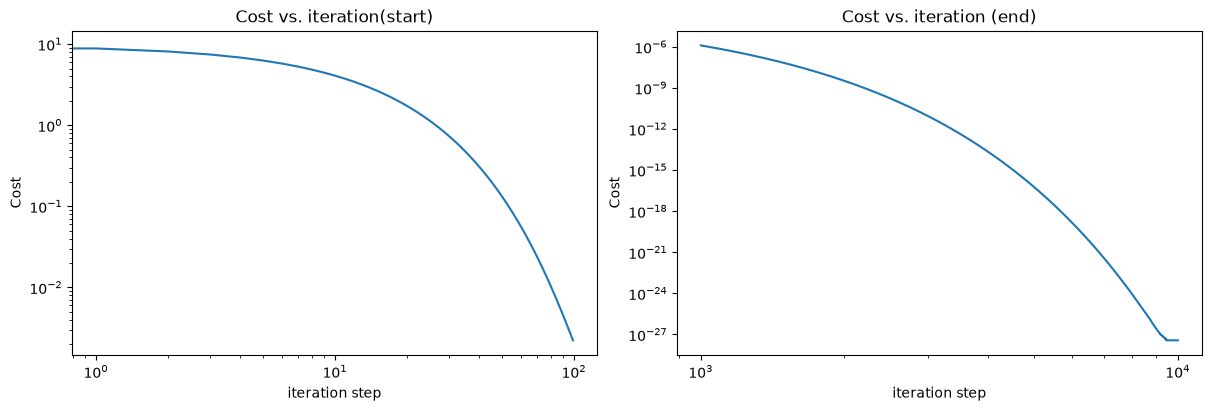

In [10]:
# plot cost versus iteration  
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12,4))
ax1.plot(J_hist[:100])
ax2.plot(1000 + np.arange(len(J_hist[1000:])), J_hist[1000:])
ax1.set_title("Cost vs. iteration(start)");  ax2.set_title("Cost vs. iteration (end)")
ax1.set_ylabel('Cost')            ;  ax2.set_ylabel('Cost') 
ax1.set_xlabel('iteration step')  ;  ax2.set_xlabel('iteration step') 
ax1.set_xscale('log')             ;  ax2.set_xscale('log')
ax1.set_yscale('log')             ;  ax2.set_yscale('log')
plt.show()

<a name="toc_40291_2.6"></a>
## Plotting
You can show the progress of gradient descent during its execution by plotting the cost over iterations on a contour plot of the cost(w,b). 

<a name="toc_40291_2.7.1"></a>
### Increased Learning Rate

<figure>
 <img align="left", src="./images/C1_W1_Lab03_alpha_too_big.PNG"   style="width:340px;height:240px;" >
</figure>
In the lecture, there was a discussion related to the proper value of the learning rate, $\alpha$ in equation(3). The larger $\alpha$ is, the faster gradient descent will converge to a solution. But, if it is too large, gradient descent will diverge. Above you have an example of a solution which converges nicely.

Let's try increasing the value of  $\alpha$ and see what happens:

In [19]:
# initialize parameters
w_init = 0
b_init = 0
# set alpha to a large value
iterations = 1000
tmp_alpha_list = [1.0e-0, 1.0e-2, 1.0e-3]
# run gradient descent
for tmp_alpha in tmp_alpha_list:
    print(f"Running gradient descent with alpha = {tmp_alpha}")    
    w_final, b_final, J_hist, p_hist = gradient_descent(x_train ,y_train, w_init, b_init, tmp_alpha, 
                                                        iterations, compute_cost, compute_gradient)

Running gradient descent with alpha = 1.0
Iteration    0: Cost 1.08e+02  dj_dw: -8.500e+00, dj_db: -4.000e+00   w:  8.500e+00, b: 4.00000e+00
Iteration  100: Cost 1.35e+103  dj_dw: -3.017e+51, dj_db: -1.413e+51   w:  2.299e+51, b: 1.07678e+51
Iteration  200: Cost 1.70e+204  dj_dw: -1.070e+102, dj_db: -5.011e+101   w:  8.153e+101, b: 3.81844e+101
Iteration  300: Cost 2.14e+305  dj_dw: -3.794e+152, dj_db: -1.777e+152   w:  2.891e+152, b: 1.35409e+152
Iteration  400: Cost inf  dj_dw: -1.345e+203, dj_db: -6.301e+202   w:  1.025e+203, b: 4.80182e+202
Iteration  500: Cost inf  dj_dw: -4.771e+253, dj_db: -2.235e+253   w:  3.636e+253, b: 1.70281e+253
Iteration  600: Cost inf  dj_dw: -1.692e+304, dj_db: -7.924e+303   w:  1.289e+304, b: 6.03847e+303
Iteration  700: Cost nan  dj_dw:  nan, dj_db:  nan   w:  nan, b: nan
Iteration  800: Cost nan  dj_dw:  nan, dj_db:  nan   w:  nan, b: nan
Iteration  900: Cost nan  dj_dw:  nan, dj_db:  nan   w:  nan, b: nan
Running gradient descent with alpha = 0.01


/var/folders/4h/fr3g4ffn0_x0f8512mwxtcnw0000gn/T/ipykernel_2707/586719361.py:9: RuntimeWarning: overflow encountered in scalar add
  cost = cost + (f_wb - y[i])**2
/var/folders/4h/fr3g4ffn0_x0f8512mwxtcnw0000gn/T/ipykernel_2707/586719361.py:9: RuntimeWarning: overflow encountered in scalar power
  cost = cost + (f_wb - y[i])**2
/var/folders/4h/fr3g4ffn0_x0f8512mwxtcnw0000gn/T/ipykernel_2707/255131020.py:23: RuntimeWarning: overflow encountered in scalar add
  dj_dw += dj_dw_i
/var/folders/4h/fr3g4ffn0_x0f8512mwxtcnw0000gn/T/ipykernel_2707/586719361.py:8: RuntimeWarning: invalid value encountered in scalar multiply
  f_wb = w * x[i] + b
/var/folders/4h/fr3g4ffn0_x0f8512mwxtcnw0000gn/T/ipykernel_2707/255131020.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  f_wb = w * x[i] + b


Above, $w$ and $b$ are bouncing back and forth between positive and negative with the absolute value increasing with each iteration. Further, each iteration $\frac{\partial J(w,b)}{\partial w}$ changes sign and cost is increasing rather than decreasing. This is a clear sign that the *learning rate is too large* and the solution is diverging. 
Let's visualize this with a plot.


## Congratulations!
In this lab you:
- delved into the details of gradient descent for a single variable.
- developed a routine to compute the gradient
- visualized what the gradient is
- completed a gradient descent routine
- utilized gradient descent to find parameters
- examined the impact of sizing the learning rate